In [ ]:
# 01 preprocessing — Wang 2019 GBM (10x). Load malignant cells, integrate on sample,
# regenerate the embedding, judge Gate 1 on the embedding + per-neighbourhood iLISI.
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# paths: cwd = <root>/mesencontext/claude/<Category>/<Dataset>-4  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Wang2019_Brain-4'
stem = re.sub(r'-\d+$', '', name)                       # 'Wang2019_Brain' (input has no -N suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + stem)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+stem)

dataset: Wang2019_Brain-4 | category: Brain | input: Data_Wang2019_Brain


In [ ]:
# load malignant cells (Wang 2019 = single 10x leaf; UMIcounts -> normalize_total+log1p by loader)
adata = load_CCCA_adata(pth_in, verbose=False); adata.var_names_make_unique()
print('all cell types:', adata.obs.cell_type.value_counts().to_dict())
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant:', adata.shape, '| Xmax %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())
# keep useful obs, coerce dtypes (precomputed cell-cycle cols are all-NaN here)
obs = pd.DataFrame(index=adata.obs_names)
obs['sample'] = adata.obs['sample'].astype(str)
obs['mp_top'] = adata.obs['mp_top'].astype(str)          # 3CA meta-program call (publication reference)
obs['complexity'] = pd.to_numeric(adata.obs['complexity'], errors='coerce')
adata.obs = obs; adata.obs['cell_type'] = 'Malignant'
CELLS_MALIGNANT_RAW = adata.shape[0]
print('CellsMalignantRaw =', CELLS_MALIGNANT_RAW)

all cell types: {'Malignant': 9916, 'Oligodendrocyte': 3711, 'Myeloid': 2396, 'Astrocyte': 248, 'Endothelial': 46}
malignant: (9916, 33545) | Xmax 7.51 (log1p of normalize_total UMIcounts)
CellsMalignantRaw = 9916


In [ ]:
# cell-cycle score (precomputed columns are NaN for malignant cells) — needed for the cycling check
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phase: {'G1': 7945, 'G2M': 1019, 'S': 952}


In [ ]:
# per-sample min-cell threshold: derive from the largest multiplicative gap (geometric mean across it)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print('adjacent ratios:', np.round(ratios,2).tolist())
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) -> threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
CELLS_AFTER_THRESHOLD = adata.shape[0]
print(f'kept {len(keep)}/{len(n)} samples -> CellsAfterThreshold = {CELLS_AFTER_THRESHOLD}')

sorted per-sample counts: [2732, 2492, 1293, 1112, 938, 687, 396, 143, 85, 38]
adjacent ratios: [1.1, 1.93, 1.16, 1.19, 1.37, 1.73, 2.77, 1.68, 2.24]
largest gap: 396 -> 143 (ratio 2.77) -> threshold = 237
kept 7/10 samples -> CellsAfterThreshold = 9650


In [ ]:
# genes, overdispersion, PCA; pick n_pcs from the scree
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cumulative variance @ pcs 10/20/30/40:', [round(float(vr[:k].sum()),3) for k in [10,20,30,40]])
N_PCS = 20   # matches Brain/10x precedents (Neftel 20); >20 adds <2% variance
print('n_pcs =', N_PCS)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 2113
cumulative variance @ pcs 10/20/30/40: [0.396, 0.438, 0.461, 0.477]
n_pcs = 20


In [ ]:
# Gate-1 integration sweep: per-neighbourhood iLISI (NOT a scalar) across Harmony strength
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}):')
print('  pre-Harmony PCA(%d): %.2f' % (N_PCS, ilisi(adata.obsm['X_pca'][:,:N_PCS], s)))
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], s)))
THETA = 10
print('selected theta =', THETA, '(mixing plateaus by 10; 20 adds nothing -> strongest integration w/o collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=30, random_state=SEED)

sample iLISI (ideal 7):
  pre-Harmony PCA(20): 1.03
2026-08-07 21:20:00,322 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 21:20:01,520 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 21:20:01,575 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 21:20:03,844 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 21:20:06,064 - harmonypy - INFO - Converged after 2 iterations
  theta= 2: 1.69
2026-08-07 21:20:06,548 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 21:20:07,729 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 21:20:07,770 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 21:20:10,107 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 21:20:12,877 - harmonypy - INFO - Iteration 3 of 30
2026-08-07 21:20:15,561 - harmonypy - INFO - Iteration 4 of 30
2026-08-07 21:20:17,627 - harmonypy - INFO - Iteration 5 of 30
2026-08-07 21:20:19,305 - harmonypy - INFO - Iteration

In [ ]:
# neighbours + UMAP on the integrated representation
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# island removal: UMAP radius graph at 6x median NN distance, keep the largest connected component
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
sizes = pd.Series(lab).value_counts(); main = sizes.index[0]
print('connected components:', ncomp, '| sizes:', sizes.head(6).to_dict())
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached island(s)')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
CELLS_AFTER_ISLAND = adata.shape[0]
print('CellsAfterIslandRemoval =', CELLS_AFTER_ISLAND, '| sample iLISI = %.2f of %d' % (ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values), nsamp))

connected components: 2 | sizes: {0: 9634, 1: 16}
removed 16 cells in 1 detached island(s)
CellsAfterIslandRemoval = 9634 | sample iLISI = 2.60 of 7


In [ ]:
# lobes + cycling: is any sub-region a proliferation compartment that would confound the axis?
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
print('-> cycling cells are a scattered minority (no lobe is a distinct proliferation compartment);')
print('   orthogonality to the embryonic modules is confirmed quantitatively in 02_manifold.')

lobe sizes: {'1': 2801, '0': 2145, '2': 1988, '3': 1556, '4': 1090, '5': 54}
cycling fraction per lobe: {'0': 0.16, '1': 0.26, '2': 0.12, '3': 0.17, '4': 0.29, '5': 0.43}
-> cycling cells are a scattered minority (no lobe is a distinct proliferation compartment);
   orthogonality to the embryonic modules is confirmed quantitatively in 02_manifold.


In [ ]:
# GBM cellular-state annotation: BOTH data-derived markers AND the publication's reported states.
# Wang et al. 2019 (Cancer Discovery) model GBM as a single axis of variation; the field-standard
# Neftel/Suva states (AC / MES / OPC / NPC-like) are scored here and cross-checked against the 3CA
# meta-program calls carried in the input (obs['mp_top']).
states = {'AC-like':['GFAP','AQP4','S100B','MLC1','HOPX','CLU','SPARCL1'],
          'MES-like':['CHI3L1','CD44','ANXA1','ANXA2','LGALS1','LGALS3','VIM'],
          'OPC-like':['OLIG1','OLIG2','PDGFRA','CSPG4','SOX10','APOD'],
          'NPC-like':['DLL3','SOX2','CD24','STMN2','DCX','SOX11','TCF4']}
for st, gl in states.items():
    sc.tl.score_genes(adata, [g for g in gl if g in adata.var_names], score_name=st, random_state=1234)
adata.obs['subtype'] = adata.obs[list(states)].idxmax(1).str.replace('-like','')
adata.obs['subtype'] = adata.obs['subtype'].astype('category')
print('subtype (data-derived, argmax state score):', adata.obs['subtype'].value_counts().to_dict())
top3 = adata.obs['mp_top'].value_counts().head(6)
print('3CA meta-program (publication reference), top:', top3.to_dict())

subtype (data-derived, argmax state score): {'NPC': 4739, 'AC': 2770, 'MES': 1196, 'OPC': 929}
3CA meta-program (publication reference), top: {'Oligo Progenitor': 1708, 'NPC/OPC': 1575, 'Astrocytes': 1415, 'nan': 1035, 'Hypoxia': 777, 'MES (glioma)': 489}


saved samples.pdf


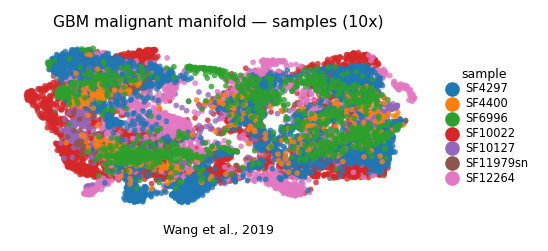

In [ ]:
# GATE 1 figure: single sample-coloured manifold (house (3.5,1.5) linear-trajectory aspect)
plot = adata.copy(); xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')

In [ ]:
# GATE 1 verdict: samples intermix on ONE connected continuous manifold (iLISI rose 1.0 -> ~2.6/7
# under Harmony, plateauing by theta=10; a single 16-cell island removed; no per-sample archipelago).
print('GATE 1 (mixing & continuity): GO')
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

GATE 1 (mixing & continuity): GO
saved processed.h5ad (9634, 26409)
